<a href="https://colab.research.google.com/github/wadeea23/ECG-Based-Heartbeat-Classification-Using-Machine-Learning/blob/main/ECG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install wfdb

In [2]:
! pip install tensorflow

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import zipfile

zip_path = '/content/drive/MyDrive/GA/Capstone_GA/mitdb-1.0.0.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/mitdb-1.0.0')

In [6]:
import wfdb
import os
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split , GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, MaxPooling1D, Flatten
from sklearn.preprocessing import StandardScaler , LabelEncoder
import tensorflow as tf
import pandas as pd
from imblearn.over_sampling import SMOTE
import joblib

In [7]:
folder = '/content/mitdb-1.0.0/mit-bih-arrhythmia-database-1.0.0'

print(os.listdir(folder))

['203.at-', '233.hea', '228.dat', '212.hea', '202.atr', '123.dat', '201.hea', '121.xws', '207.hea', '212.xws', '108.dat', '230.hea', '203.at_', '101.xws', '219.dat', '208.atr', '214.xws', '101.atr', '202.xws', '104.atr', '124.hea', '118.atr', '232.atr', '231.xws', '123.atr', '233.dat', '113.xws', '220.hea', '108.at_', '210.atr', '121.hea', '104.hea', '219.hea', '233.atr', '123.hea', '201.xws', '109.atr', '209.xws', '114.hea', '234.xws', '111.hea', '209.at_', '122.atr', '210.hea', '121.atr', '221.atr', '205.atr', '201.dat', '124.xws', '114.atr', '103.atr', '118.xws', '207.xws', '104.xws', '208.xws', '124.atr', '213.hea', '107.dat', '111.dat', '111.atr', '212.dat', '124.dat', '112.hea', '116.hea', '234.atr', '207.dat', '234.hea', '102.hea', '209.dat', '230.dat', '200.dat', '212.atr', '112.xws', '100.dat', '220.xws', '221.hea', '116.atr', '114.xws', '105.hea', '100.xws', '231.dat', '203.xws', '208.hea', '106.xws', '102.dat', '222.xws', '232.dat', '209.hea', '217.dat', '223.dat', '234.dat'

In [8]:
files = os.listdir(folder)

dat_count = str(files).count('.dat')
hea_count = str(files).count('.hea')
atr_count = str(files).count('.atr')

print("DAT:", dat_count)
print("HEA:", hea_count)
print("ATR:", atr_count)

DAT: 48
HEA: 48
ATR: 49


In [9]:
all_labels = []  # عشان اجوف كل الرموز اللي في الديتا سيت و شلون اخليهم مع بعض عقب
signals = []
for file in files:  # هاي الرموز ف ديتا سيت و صنفناهم  ع حسب المعيار العلمي

    if file.endswith('.hea'):

        name = file.replace('.hea', '')
        record = wfdb.rdrecord(folder + '/' + name)
        signal = record.p_signal[:, 0]
        signals.append(signal)
        annotation = wfdb.rdann(folder + '/' + name, 'atr')

        all_labels = all_labels + annotation.symbol

print("Signals:", len(signals))
print("Labels:", len(all_labels))
print("Label Types:", set(all_labels))


Signals: 48
Labels: 112647
Label Types: {'a', '[', '|', 'Q', 'S', 'j', ']', 'e', 'L', 'V', '~', '"', 'F', 'A', 'N', 'E', 'x', '+', '/', 'f', '!', 'R', 'J'}


In [10]:
# convert all clissy to aami in all records
N = all_labels.count('N') + all_labels.count('L') + all_labels.count('R') + all_labels.count('e') + all_labels.count('j')

S = all_labels.count('A') + all_labels.count('a') + all_labels.count('J') + all_labels.count('S')

V = all_labels.count('V') + all_labels.count('E')

F = all_labels.count('F')

Q = all_labels.count('/') + all_labels.count('f') + all_labels.count('Q')

print("N:", N)
print("S:", S)
print("V:", V)
print("F:", F)
print("Q:", Q)

N: 90631
S: 2781
V: 7236
F: 803
Q: 8043


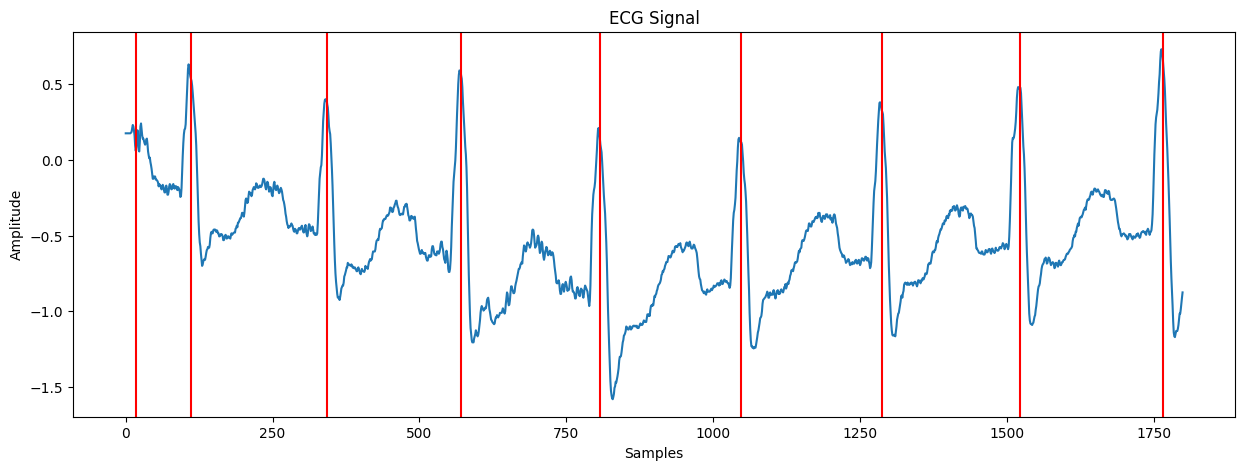

In [11]:
plt.figure(figsize=(15, 5))

plt.plot(signal[:1800]) # i choose 1800 / 360 hz = 5 sec

for peak in annotation.sample:
    if peak < 1800:
        plt.axvline(peak, color='red') # يحدد مكان النبض بالخطوط الطولية

plt.title('ECG Signal')
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.show()

In [12]:
# Heartbeat to prepare the data to train models

In [13]:
# i will prapare the data to 48 record

In [14]:
X = []
y = []

for file in files:

    if file.endswith('.hea'):

        name = file.replace('.hea', '')

        record = wfdb.rdrecord(folder + '/' + name)
        annotation = wfdb.rdann(folder + '/' + name, 'atr')

        signal = record.p_signal[:, 0]

        for i in range(len(annotation.sample)):

            peak = annotation.sample[i]
            label = annotation.symbol[i]

            if label in ['N', 'L', 'R', 'e', 'j']:
                label = 'N'

            elif label in ['A', 'a', 'J', 'S']:
                label = 'S'

            elif label in ['V', 'E']:
                label = 'V'

            elif label != 'F':
                continue

            if peak >= 120 and peak + 240 <= len(signal):

                beat = signal[peak-120:peak+240]

                X.append(beat)
                y.append(label)

X = np.array(X)
y = np.array(y)

X = (X - X.mean(axis=1, keepdims=True)) / (X.std(axis=1, keepdims=True) + 0.00000001)

print("X Shape:", X.shape)
print("Y Shape:", y.shape)

X Shape: (101396, 360)
Y Shape: (101396,)


In [15]:
# model 1 split the data

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42,stratify=y_train)

In [17]:
# model 1 binary classify 0=normal / 1=abnormal

In [18]:
y_train_binary = (y_train != 'N').astype(int) # to convert n to 0 other to 1
y_val_binary = (y_val != 'N').astype(int)
y_test_binary = (y_test != 'N').astype(int)

In [19]:
# model 2 to classfy abnormal

In [20]:
X_train_2 = X_train[y_train != 'N'] # remove all normal
y_train_2 = y_train[y_train != 'N']

X_val_2 = X_val[y_val != 'N']
y_val_2 = y_val[y_val != 'N']

X_test_2 = X_test[y_test != 'N']
y_test_2 = y_test[y_test != 'N']

In [21]:
## dt for bainary model

In [22]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train_binary)

pred = dt_model.predict(X_val)

print(classification_report(y_val_binary, pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      9058
           1       0.85      0.86      0.86      1082

    accuracy                           0.97     10140
   macro avg       0.92      0.92      0.92     10140
weighted avg       0.97      0.97      0.97     10140



In [23]:
pred = dt_model.predict(X_test)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     18117
           1       0.86      0.85      0.86      2163

    accuracy                           0.97     20280
   macro avg       0.92      0.92      0.92     20280
weighted avg       0.97      0.97      0.97     20280



In [24]:
# knn model

In [25]:
scaler = StandardScaler()   # preprocessing
X_train_scaler = scaler.fit_transform(X_train)
X_val_scaler = scaler.transform(X_val)
X_test_scaler = scaler.transform(X_test)

In [26]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaler, y_train_binary)

knn_pred = knn_model.predict(X_val_scaler)

print(classification_report(y_val_binary, knn_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      9058
           1       0.97      0.92      0.95      1082

    accuracy                           0.99     10140
   macro avg       0.98      0.96      0.97     10140
weighted avg       0.99      0.99      0.99     10140



In [27]:
pred = knn_model.predict(X_test_scaler)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     18117
           1       0.97      0.90      0.93      2163

    accuracy                           0.99     20280
   macro avg       0.98      0.95      0.96     20280
weighted avg       0.99      0.99      0.99     20280



In [28]:
# cnn model

In [29]:
X_train_cnn = X_train.reshape(-1, 360, 1)
X_val_cnn = X_val.reshape(-1, 360, 1)
X_test_cnn = X_test.reshape(-1, 360, 1)

cnn_model = Sequential()

cnn_model.add(Conv1D(32, 3, activation='relu', input_shape=(360, 1)))
cnn_model.add(MaxPooling1D(2))

cnn_model.add(Conv1D(64, 3, activation='relu'))
cnn_model.add(MaxPooling1D(2))

cnn_model.add(Flatten())

cnn_model.add(Dense(64, activation='relu'))
cnn_model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [30]:
cnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


In [31]:
cnn_model.fit(X_train_cnn, y_train_binary, epochs=10, validation_data=(X_val_cnn, y_val_binary))


Epoch 1/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 31s 13ms/step - accuracy: 0.9743 - loss: 0.0862 - val_accuracy: 0.9864 - val_loss: 0.0501
Epoch 2/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 30s 14ms/step - accuracy: 0.9859 - loss: 0.0458 - val_accuracy: 0.9897 - val_loss: 0.0399
Epoch 3/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 30s 14ms/step - accuracy: 0.9896 - loss: 0.0336 - val_accuracy: 0.9893 - val_loss: 0.0379
Epoch 4/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 30s 13ms/step - accuracy: 0.9916 - loss: 0.0268 - val_accuracy: 0.9901 - val_loss: 0.0336
Epoch 5/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 42s 14ms/step - accuracy: 0.9929 - loss: 0.0220 - val_accuracy: 0.9923 - val_loss: 0.0335
Epoch 6/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 29s 13ms/step - accuracy: 0.9943 - loss: 0.0172 - val_accuracy: 0.9896 - val_loss: 0.0403
Epoch 7/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 30s 13ms/step - accuracy: 0.9952 - loss: 0.0149 - val_accuracy: 0.9902 - val_loss: 0.0393
Epoch 8/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 31s 14ms/step - accuracy: 0.9960 -

In [32]:
pred = (cnn_model.predict(X_val_cnn) > 0.5).astype(int)

print(classification_report(y_val_binary, pred))

317/317 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      9058
           1       0.98      0.93      0.96      1082

    accuracy                           0.99     10140
   macro avg       0.99      0.97      0.98     10140
weighted avg       0.99      0.99      0.99     10140



In [33]:
cnn_pred = (cnn_model.predict(X_test_cnn) > 0.5).astype(int)

print(classification_report(y_test_binary, cnn_pred))

634/634 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     18117
           1       0.98      0.92      0.95      2163

    accuracy                           0.99     20280
   macro avg       0.99      0.96      0.97     20280
weighted avg       0.99      0.99      0.99     20280



In [34]:
best_model=cnn_model
best_model.save('best_bainary_model.keras')

In [35]:
best_model = tf.keras.models.load_model('best_bainary_model.keras')

In [36]:
# model 2 to clissfy abnormal

In [37]:
# dt2

In [38]:
dt2_model = DecisionTreeClassifier(random_state=42)

dt2_model.fit(X_train_2, y_train_2)

dt2_pred = dt2_model.predict(X_val_2)

print(classification_report(y_val_2, dt2_pred))

              precision    recall  f1-score   support

           F       0.78      0.76      0.77        80
           S       0.93      0.95      0.94       278
           V       0.97      0.96      0.97       724

    accuracy                           0.95      1082
   macro avg       0.89      0.89      0.89      1082
weighted avg       0.95      0.95      0.95      1082



In [39]:
# knn2

In [40]:
scaler2 = StandardScaler()

X_train_scaled = scaler2.fit_transform(X_train_2)
X_val_scaled = scaler2.transform(X_val_2)

In [41]:
knn2_model = KNeighborsClassifier(n_neighbors=5)

knn2_model.fit(X_train_scaled, y_train_2)

knn2_pred = knn2_model.predict(X_val_scaled)

print(classification_report(y_val_2, knn2_pred))

              precision    recall  f1-score   support

           F       0.84      0.82      0.83        80
           S       0.96      0.98      0.97       278
           V       0.98      0.98      0.98       724

    accuracy                           0.96      1082
   macro avg       0.93      0.93      0.93      1082
weighted avg       0.96      0.96      0.96      1082



In [42]:
#cnn2

In [43]:
X_train_cnn2 = X_train_2.reshape(-1, 360, 1)
X_val_cnn2 = X_val_2.reshape(-1, 360, 1)
X_test_cnn2 = X_test_2.reshape(-1, 360, 1)

In [44]:
encoder2 = LabelEncoder()

y_train_encoded = encoder2.fit_transform(y_train_2)
y_val_encoded = encoder2.transform(y_val_2)
y_test_encoded = encoder2.transform(y_test_2)

In [45]:
class_names = {
    'F': 'Fusion Beat',
    'S': 'Supraventricular Ectopic Beat',
    'V': 'Ventricular Ectopic Beat'
}

In [46]:
cnn2_model = Sequential()

cnn2_model.add(Conv1D(32, 3, activation='relu', input_shape=(360, 1)))
cnn2_model.add(MaxPooling1D(2))

cnn2_model.add(Conv1D(64, 3, activation='relu'))
cnn2_model.add(MaxPooling1D(2))

cnn2_model.add(Flatten())

cnn2_model.add(Dense(64, activation='relu'))
cnn2_model.add(Dense(3, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [47]:
cnn2_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [48]:
history2 = cnn2_model.fit(X_train_cnn2,y_train_encoded,epochs=20,batch_size=32,validation_data=(X_val_cnn2, y_val_encoded)
)

Epoch 1/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9424 - loss: 0.1702 - val_accuracy: 0.9529 - val_loss: 0.1255
Epoch 2/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9645 - loss: 0.0999 - val_accuracy: 0.9492 - val_loss: 0.1171
Epoch 3/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9745 - loss: 0.0744 - val_accuracy: 0.9695 - val_loss: 0.0830
Epoch 4/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9785 - loss: 0.0601 - val_accuracy: 0.9686 - val_loss: 0.0897
Epoch 5/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9834 - loss: 0.0458 - val_accuracy: 0.9713 - val_loss: 0.1032
Epoch 6/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9868 - loss: 0.0386 - val_accuracy: 0.9704 - val_loss: 0.1033
Epoch 7/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9884 - loss: 0.0318 - val_accuracy: 0.9723 - val_loss: 0.0888
Epoch 8/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9904 - loss: 0.0261 - val_accu

In [49]:
cnn2_pred = cnn2_model.predict(X_val_cnn2)

cnn2_pred = np.argmax(cnn2_pred, axis=1)

predicted_labels = encoder2.inverse_transform(cnn2_pred)

full_names = [class_names[label] for label in predicted_labels]

print(full_names[:10])

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
['Supraventricular Ectopic Beat', 'Ventricular Ectopic Beat', 'Supraventricular Ectopic Beat', 'Supraventricular Ectopic Beat', 'Supraventricular Ectopic Beat', 'Ventricular Ectopic Beat', 'Ventricular Ectopic Beat', 'Supraventricular Ectopic Beat', 'Ventricular Ectopic Beat', 'Ventricular Ectopic Beat']


In [50]:
print(classification_report(y_val_encoded, cnn2_pred,target_names=encoder2.classes_))

              precision    recall  f1-score   support

           F       0.83      0.90      0.86        80
           S       0.99      0.99      0.99       278
           V       0.99      0.98      0.98       724

    accuracy                           0.97      1082
   macro avg       0.93      0.96      0.94      1082
weighted avg       0.98      0.97      0.97      1082



In [51]:
cnn2_test_pred = cnn2_model.predict(X_test_cnn2)

cnn2_test_pred = np.argmax(cnn2_test_pred, axis=1)

print(classification_report(y_test_encoded, cnn2_test_pred,target_names=encoder2.classes_))

68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
              precision    recall  f1-score   support

           F       0.84      0.88      0.86       160
           S       0.96      0.98      0.97       556
           V       0.98      0.97      0.98      1447

    accuracy                           0.97      2163
   macro avg       0.93      0.94      0.94      2163
weighted avg       0.97      0.97      0.97      2163



In [52]:
cnn2_model.save('cnn2_model.keras')

In [53]:
joblib.dump(encoder2, 'encoder2.pkl')

['encoder2.pkl']

In [54]:
normal = X_test[y_test == 'N']
abnormal = X_test[y_test != 'N']

pd.DataFrame(normal[:100]).to_csv("normal.csv", index=False, header=False)

pd.DataFrame(abnormal[:100]).to_csv("abnormal.csv", index=False, header=False)

pd.DataFrame(X_test[:200]).to_csv("mixed.csv", index=False, header=False)

In [55]:
from google.colab import files

files.download("normal.csv")
files.download("abnormal.csv")
files.download("mixed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>